In [2]:
import pandas as pd
import random
import numpy as np
import torch
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from utils import load_splits

In [3]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
device

device(type='cuda')

In [4]:
#global random seed
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

In [5]:
X_train, X_val, X_test, y_train, y_val, y_test = load_splits()

In [6]:
for name, X, y in [
    ("Train", X_train, y_train),
    ("Validation", X_val, y_val),
    ("Test", X_test, y_test)
]:
    print(f"{name}: {len(X)} samples")
    print(y.value_counts(normalize=True))
    print()

Train: 43554 samples
labels
0    0.555678
1    0.444322
Name: proportion, dtype: float64

Validation: 9333 samples
labels
0    0.555663
1    0.444337
Name: proportion, dtype: float64

Test: 9333 samples
labels
0    0.55577
1    0.44423
Name: proportion, dtype: float64



In [7]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        stop_words= "english",
        lowercase= True,
        norm = "l2"
        )
    ),
    ("clf", LogisticRegression(max_iter=1000))
])

param_grid = {
    "tfidf__max_features": [10000, 20000],
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "tfidf__min_df": [2, 5],
    "tfidf__sublinear_tf": [False, True],
    "clf__C": [0.1, 1.0, 10.0]
}

grid = GridSearchCV(
    pipeline,
    param_grid,
    cv=3,
    scoring="f1_macro",
    n_jobs=-1
)

grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best CV F1:", grid.best_score_)

Best parameters: {'clf__C': 10.0, 'tfidf__max_features': 20000, 'tfidf__min_df': 2, 'tfidf__ngram_range': (1, 2), 'tfidf__sublinear_tf': True}
Best CV F1: 0.8858001177900064


In [8]:
y_pred = grid.predict(X_val)
report = classification_report(
    y_val,
    y_pred,
    labels=[0,1],
    target_names=["True", "Fake"],
    digits=2
)
print(report)

              precision    recall  f1-score   support

        True       0.90      0.90      0.90      5186
        Fake       0.88      0.88      0.88      4147

    accuracy                           0.89      9333
   macro avg       0.89      0.89      0.89      9333
weighted avg       0.89      0.89      0.89      9333



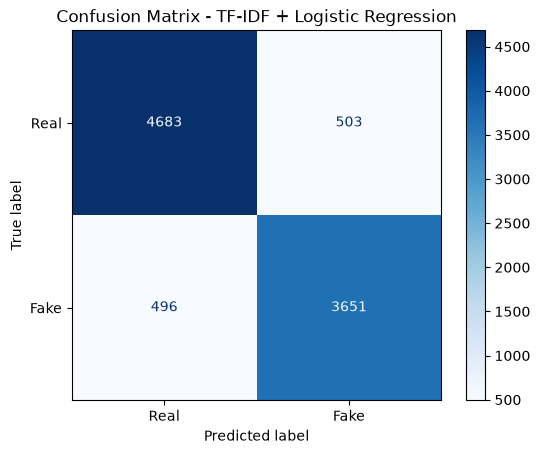

In [9]:
ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred,
    labels=[0, 1],
    display_labels=["Real", "Fake"],
    cmap="Blues",
    values_format="d"
)

plt.title("Confusion Matrix - TF-IDF + Logistic Regression")
plt.show()

In [11]:
import joblib

joblib.dump(grid.best_estimator_, "models/logstic_regression_model.pkl")

['models/logstic_regression_model.pkl']